# Assignment 58 — Week 7, Day 2
## Topic: Deep Learning — Feed-Forward Neural Networks

**Objective:** Complete the exercise on feed-forward neural networks.

**Reference:** https://builtin.com/data-science/feedforward-neural-network-intro

A **feed-forward neural network** is the simplest kind of artificial neural network: information moves in **one direction only**, from the input layer, through any hidden layers, to the output layer. There are no cycles or loops, unlike recurrent networks.

Following the Built In introduction, the main ideas are:

- **Layers** – input, hidden and output layers made of neurons (nodes).
- **Weights and biases** – each connection has a weight; each neuron has a bias.
- **Activation functions** – add non-linearity so the network can learn curved patterns.
- **Training** – the output is compared with the target using a **cost (loss) function**, and **gradient descent** with backpropagation adjusts the weights to reduce it.

**Diagram:** In a feed-forward network data flows straight through; a recurrent network loops outputs back.

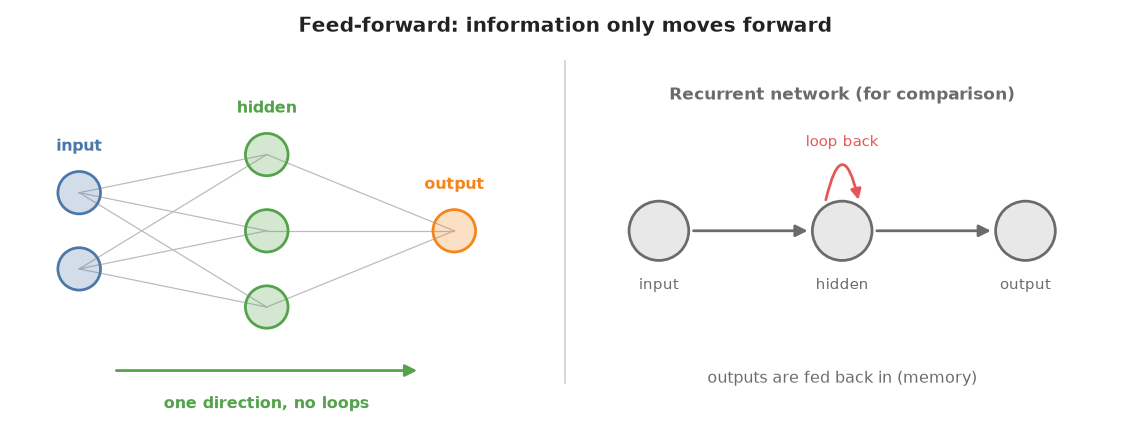

**Set up TensorFlow and Keras**

In [1]:
import os
import logging

# Hide TensorFlow's start-up log messages so the outputs stay readable
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"
logging.getLogger("tensorflow").setLevel(logging.ERROR)

import numpy as np
import tensorflow as tf
from tensorflow import keras

tf.get_logger().setLevel(logging.ERROR)
keras.utils.set_random_seed(42)  # makes the results repeatable
print("TensorFlow", tf.__version__)

TensorFlow 2.21.0


**Explanation:** The setup cell imports NumPy, TensorFlow and Keras, hides TensorFlow's log messages and fixes the random seed.

**Diagram:** The calculation a feed-forward network performs for one input.

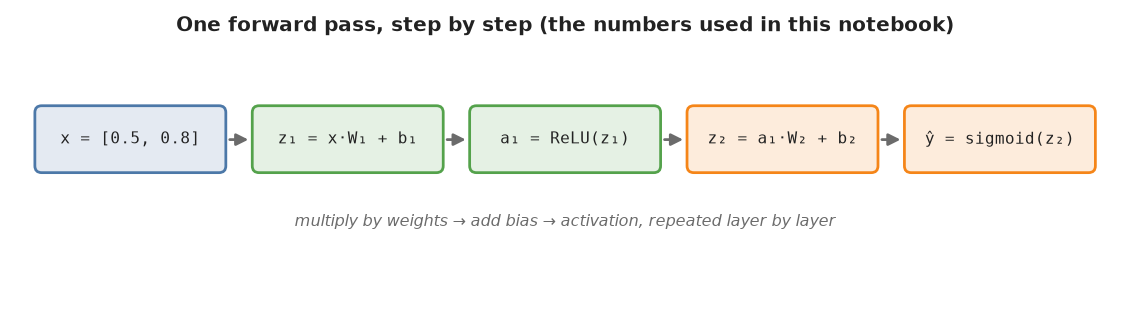

**A forward pass by hand with NumPy**

In [2]:
import numpy as np

def relu(z):
    return np.maximum(0, z)

def sigmoid(z):
    return 1 / (1 + np.exp(-z))

x = np.array([0.5, 0.8])                         # 2 input features

W1 = np.array([[0.2, -0.4, 0.7],
               [0.9,  0.1, -0.3]])               # 2 inputs -> 3 hidden neurons
b1 = np.array([0.1, 0.0, -0.1])
W2 = np.array([[0.6], [-0.2], [0.8]])            # 3 hidden -> 1 output
b2 = np.array([0.05])

z1 = x @ W1 + b1
a1 = relu(z1)
z2 = a1 @ W2 + b2
y_hat = sigmoid(z2)

print("hidden pre-activation z1:", z1.round(3))
print("hidden activation a1:    ", a1.round(3))
print("output pre-activation z2:", z2.round(3))
print("output probability ŷ:    ", y_hat.round(3))

hidden pre-activation z1: [ 0.92 -0.12  0.01]
hidden activation a1:     [0.92 0.   0.01]
output pre-activation z2: [0.61]
output probability ŷ:     [0.648]


**Explanation:** Each layer multiplies its inputs by a weight matrix, adds a bias and applies an activation. ReLU turns the negative hidden value into 0. The sigmoid at the end gives a probability. This is exactly what happens inside every feed-forward network, only with more neurons.

**Why non-linear activations matter**

In [3]:
import numpy as np

W1 = np.array([[0.2, -0.4, 0.7], [0.9, 0.1, -0.3]])
W2 = np.array([[0.6], [-0.2], [0.8]])
x = np.array([0.5, 0.8])

two_linear_layers = (x @ W1) @ W2
one_linear_layer = x @ (W1 @ W2)

print(two_linear_layers, one_linear_layer)

[0.604] [0.604]


**Explanation:** Without an activation function, two layers collapse into one: (x·W1)·W2 equals x·(W1·W2). Stacking linear layers adds nothing, so activations such as ReLU are what allow a deep network to learn non-linear patterns.

**A data set that a straight line cannot separate**

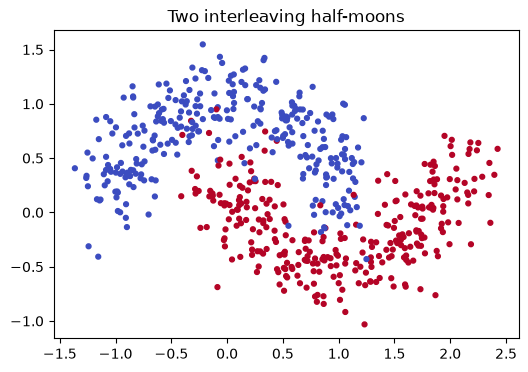

In [4]:
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons

X, y = make_moons(n_samples=600, noise=0.2, random_state=42)

plt.figure(figsize=(6, 4))
plt.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm", s=12)
plt.title("Two interleaving half-moons")
plt.show()

**Explanation:** make_moons creates two curved classes. A linear model cannot separate them, so this is a good test for a feed-forward network with hidden layers.

**Build and train a feed-forward network with Keras**

In [5]:
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from tensorflow import keras

keras.utils.set_random_seed(42)
X, y = make_moons(n_samples=600, noise=0.2, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

model = keras.Sequential([
    keras.Input(shape=(2,)),
    keras.layers.Dense(16, activation="relu"),
    keras.layers.Dense(16, activation="relu"),
    keras.layers.Dense(1, activation="sigmoid"),
])
model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
history = model.fit(X_train, y_train, epochs=100, batch_size=32, verbose=0)

print("Training accuracy:", round(history.history["accuracy"][-1], 3))
print("Test accuracy:    ", round(model.evaluate(X_test, y_test, verbose=0)[1], 3))

Training accuracy: 0.929
Test accuracy:     0.9


**Explanation:** The network has two hidden layers of 16 ReLU neurons and a sigmoid output. Data flows forward through them during prediction; during training, backpropagation and the Adam optimiser adjust the weights to reduce the binary cross-entropy loss.

**Compare with a model that has no hidden layer**

In [6]:
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from tensorflow import keras

keras.utils.set_random_seed(42)
X, y = make_moons(n_samples=600, noise=0.2, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

linear = keras.Sequential([keras.Input(shape=(2,)), keras.layers.Dense(1, activation="sigmoid")])
linear.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
linear.fit(X_train, y_train, epochs=100, batch_size=32, verbose=0)

print("No hidden layer, test accuracy:", round(linear.evaluate(X_test, y_test, verbose=0)[1], 3))

No hidden layer, test accuracy: 0.753


**Explanation:** With no hidden layer the model can only draw a straight boundary, so it gets noticeably lower accuracy on the curved moon data.

**Visualise the decision boundary**

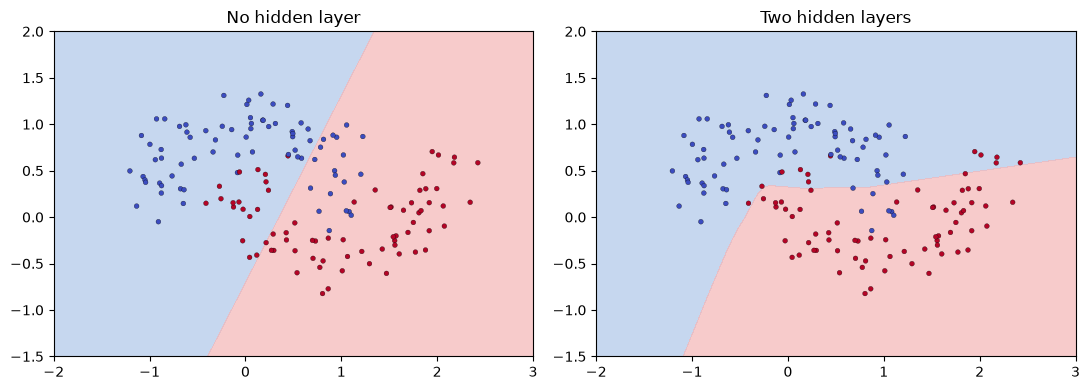

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from tensorflow import keras

keras.utils.set_random_seed(42)
X, y = make_moons(n_samples=600, noise=0.2, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

def build(hidden):
    layers = [keras.Input(shape=(2,))] + [keras.layers.Dense(16, activation="relu") for _ in range(hidden)]
    m = keras.Sequential(layers + [keras.layers.Dense(1, activation="sigmoid")])
    m.compile(optimizer="adam", loss="binary_crossentropy")
    m.fit(X_train, y_train, epochs=100, batch_size=32, verbose=0)
    return m

xx, yy = np.meshgrid(np.linspace(-2, 3, 200), np.linspace(-1.5, 2, 200))
grid_points = np.c_[xx.ravel(), yy.ravel()]

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, hidden, name in [(axes[0], 0, "No hidden layer"), (axes[1], 2, "Two hidden layers")]:
    zz = build(hidden).predict(grid_points, verbose=0).reshape(xx.shape)
    ax.contourf(xx, yy, zz, levels=[0, 0.5, 1], colors=["#AFC6E9", "#F4B6B6"], alpha=0.7)
    ax.scatter(X_test[:, 0], X_test[:, 1], c=y_test, cmap="coolwarm", s=12, edgecolors="k", linewidths=0.2)
    ax.set_title(name)
plt.tight_layout()
plt.show()

**Explanation:** The coloured regions show what each model predicts across the whole plane. Without hidden layers the boundary is a straight line; with two hidden layers the network learns a curved boundary that follows the moons.

## Observation

- In a feed-forward network, data moves in one direction from input to output, with no loops.
- Each layer multiplies by weights, adds biases and applies an activation function.
- Without non-linear activations, stacked layers collapse into a single linear layer.
- On the curved moon data, a network with hidden layers reaches much higher accuracy than one without.
- Training compares outputs with targets using a loss function and adjusts the weights with gradient descent and backpropagation.

## Conclusion

Feed-forward networks are the basic architecture of deep learning. Hidden layers with non-linear activations let them learn complex, curved patterns that simpler linear models cannot.